
# **Customer Churn Patterns in Banking — An Exploratory Study**

- Problem Statement :

A bank is losing 1 in 5 customers with no clear understanding of who is leaving or why. This project uses customer data to identify which groups are at the highest risk of leaving so the bank knows where to focus its retention efforts.

- Objective  :

    - Calculate the actual churn rate across customer segments — age, geography, gender, product count, and activity status.
    - Identify which factors have the strongest link to churn.
    - Provide a clear, data-backed starting point for retention decisions.

In [1]:
import seaborn as sb
import pandas as pd
import matplotlib.pyplot as mp
import numpy as np
import csv 
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import LabelEncoder
from scipy import stats
import statsmodels.api as sm

In [2]:
df=pd.read_csv('Churn_Modelling.csv',encoding='unicode_escape')

In [3]:
df.shape 

(10000, 14)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [5]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [6]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [7]:
df.head(10)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [8]:
df.tail(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9990,9991,15798964,Nkemakonam,714,Germany,Male,33,3,35016.60,1,1,0,53667.08,0
9991,9992,15769959,Ajuluchukwu,597,France,Female,53,4,88381.21,1,1,0,69384.71,1
9992,9993,15657105,Chukwualuka,726,Spain,Male,36,2,0.00,1,1,0,195192.40,0
9993,9994,15569266,Rahman,644,France,Male,28,7,155060.41,1,1,0,29179.52,0
9994,9995,15719294,Wood,800,France,Female,29,2,0.00,2,0,0,167773.55,0
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [9]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Zero null values found in the dataset. So there is no use of drop () and dropna().

In [10]:
# Displays datatype of all columns in the table .
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [11]:
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='str')

# Data Understanding :  **Overall Churn Rate — 20.37%** 
- 1 in 5 customers left the bank, which is a high enough number to cost the bank significant revenue every year.

In [12]:
# Overall Churn Rate 
churn_rate = df['Exited'].mean()*100
print(f"Overall Churn Rate : {round(churn_rate,2)} %")

Overall Churn Rate : 20.37 %


# Data understanding : **Overall Retention Rate — 79.63%**
- The bank is holding on to 4 out of 5 customers, but the 1 it is losing is worth focusing on before that number gets worse.

In [13]:
# Overall Retention Rate 
retention_rate = 100 - churn_rate
print(f"Overall Retention Rate : {round(retention_rate,2)} %")

Overall Retention Rate : 79.63 %


# Data understanding : **Churn by Geography**
- Germany at 32.44% versus France at 16.15% and Spain at 16.67% — the Germany gap is too large to be random and needs a direct answer.

In [14]:
# Churn Rate by Geography 
churn_geography = df.groupby('Geography')['Exited'].mean()*100
print('Churn Rate By Geography : \n', churn_geography.map(lambda x : f'{x:.1f} %').to_string())

Churn Rate By Geography : 
 Geography
France     16.2 %
Germany    32.4 %
Spain      16.7 %


# Data understanding : **Churn by Number of Products**
- 2 products is the sweet spot where customers are happiest — pushing customers beyond that is clearly driving them away.

In [15]:
print(df['NumOfProducts'].value_counts().to_string())
churn_products = df.groupby('NumOfProducts')['Exited'].mean()*100
print('\nChurn Rate By No. of products : \n', churn_products.map(lambda x : f'{x:.1f} %').to_string())



NumOfProducts
1    5084
2    4590
3     266
4      60

Churn Rate By No. of products : 
 NumOfProducts
1     27.7 %
2      7.6 %
3     82.7 %
4    100.0 %


# Data understanding : **Churn by Active Member Status**
- Inactive customers churn at 26.85% versus 14.27% for active ones — the bank should treat inactivity as a red flag, not just a usage metric.

In [16]:
churn_activemember = df.groupby('IsActiveMember')['Exited'].mean()*100
print('Churn Rate By Active Member Status ( yes =1 , no = 0 ) : \n', churn_activemember.map(lambda x : f'{x:.1f} %').to_string())

Churn Rate By Active Member Status ( yes =1 , no = 0 ) : 
 IsActiveMember
0    26.9 %
1    14.3 %


In [17]:

highest_salary = np.max(df['EstimatedSalary'])
print(f' Highest Salary : {highest_salary}')

 Highest Salary : 199992.48


# **Churn Rate by Gender graph understanding** :
- Female customers churn at 25.07% versus 16.46% for male — the bank's current products or service approach is not working equally well for both groups.

Churn Rate By Gender : 
  Gender
Female    25.07 %
Male      16.46 %


C:\Users\DELL\AppData\Local\Temp\ipykernel_1600\2831879736.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.barplot(x=churn_gender.index, y=churn_gender.values, palette="viridis")


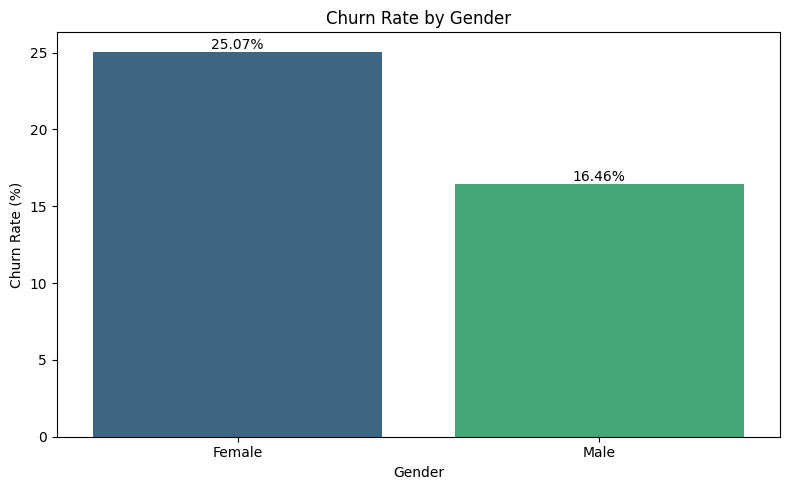

In [32]:
churn_gender = df.groupby('Gender')['Exited'].mean()*100
print('Churn Rate By Gender : \n ', churn_gender.map(lambda x : f'{x:.2f} %').to_string())

# Metric Calculation 
mp.figure(figsize=(8, 5))
ax = sb.barplot(x=churn_gender.index, y=churn_gender.values, palette="viridis")

mp.title("Churn Rate by Gender")
mp.xlabel("Gender")
mp.ylabel("Churn Rate (%)")
for bar in ax.containers:
    ax.bar_label(bar, fmt='%.2f%%')
mp.savefig('churn_rate_gender.png')
mp.tight_layout()
mp.show()



# **Churn Rate by Age Group graph Understanding** : 
- The 51–60 age group has a 56% churn rate — more than half of customers in that bracket are walking out the door.

Churn Rate By Age Group:
 AgeGroup
18-30     7.50 %
31-40    12.09 %
41-50    33.97 %
51-60    56.21 %
60+      24.78 %


C:\Users\DELL\AppData\Local\Temp\ipykernel_1600\1369188061.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.barplot(x=churn_age.index, y=churn_age.values, palette="viridis")


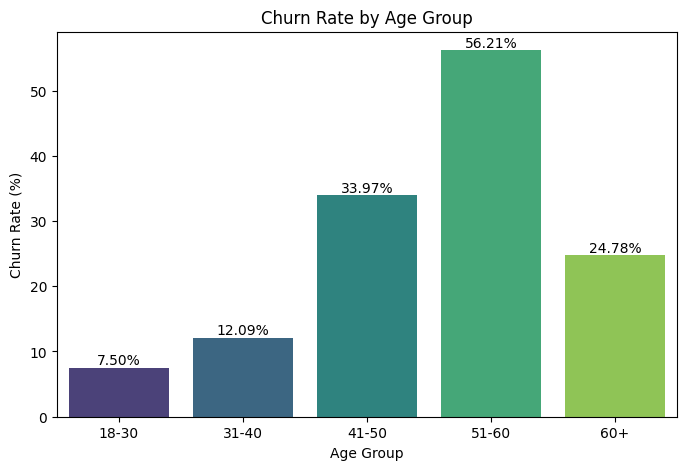

In [33]:
# Churn rate by age group
bins = [18, 30, 40, 50, 60, 100]
labels = ['18-30', '31-40', '41-50', '51-60', '60+']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)
 

churn_age = df.groupby('AgeGroup')['Exited'].mean() * 100
print('Churn Rate By Age Group:\n', churn_age.map(lambda x: f'{x:.2f} %').to_string())

# Metrics Visualization
mp.figure(figsize=(8, 5))
ax = sb.barplot(x=churn_age.index, y=churn_age.values, palette="viridis")

mp.title("Churn Rate by Age Group")
mp.xlabel("Age Group")
mp.ylabel("Churn Rate (%)")
for bar in ax.containers:
    ax.bar_label(bar, fmt='%.2f%%')
mp.savefig('churn_rate_agegroup.png')
mp.show()

 

# print("\nCustomer count by Age Group:")
# print(df['AgeGroup'].value_counts().sort_index())

# **Churn graph Understanding** :
- Shows how many customers left the bank versus how many stayed.
- Out of every 5 customers, 1 is leaving the bank — that is a serious retention problem the bank needs to address

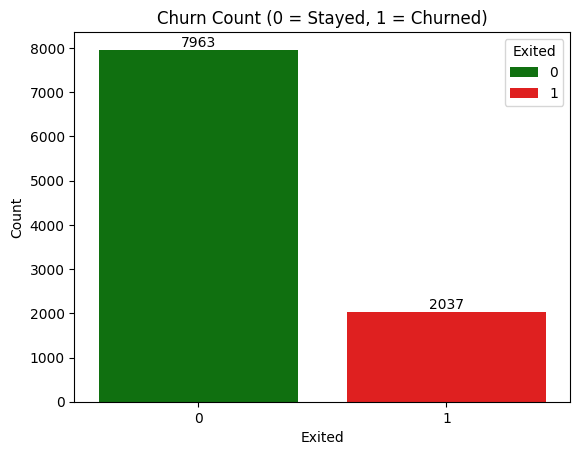

In [20]:
ax=sb.countplot(x="Exited", data=df, hue="Exited" ,palette=["green", "red"])

mp.title("Churn Count (0 = Stayed, 1 = Churned)")
mp.xlabel("Exited")
mp.ylabel("Count")
for bars in ax.containers:
    ax.bar_label(bars)
mp.show()


# **Age vs Churn Graph Understanding** :  
- The bank is losing its middle-aged and older customers the most, which are typically the highest-value segment.

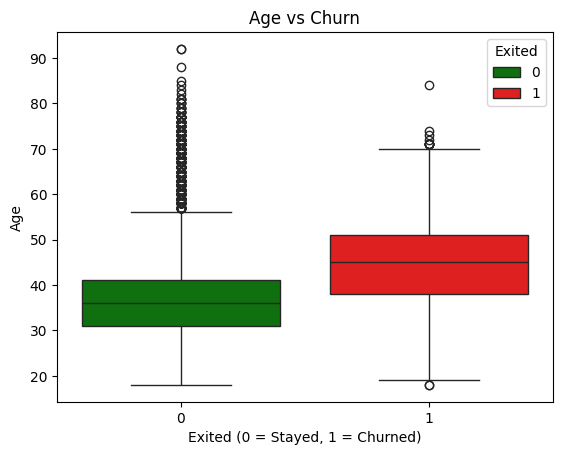

In [21]:
sb.boxplot(x="Exited", y="Age", data=df ,hue="Exited",palette=["green", "red"])

mp.title("Age vs Churn")
mp.xlabel("Exited (0 = Stayed, 1 = Churned)")
mp.ylabel("Age")
mp.show()

# **Number of Products vs Churn graph understanding** :
- Customers using 3 or 4 bank products are almost guaranteed to leave, which means offering too many products to one customer is backfiring.


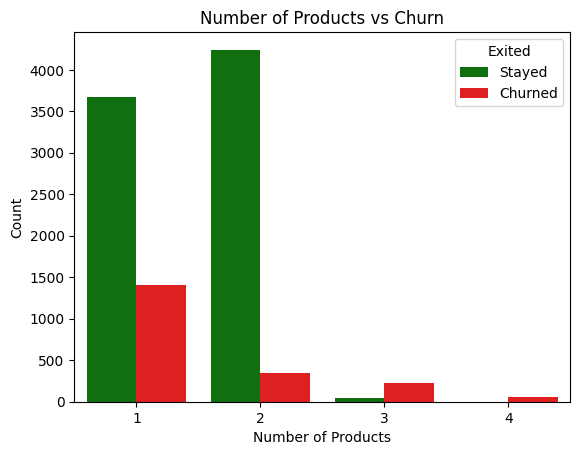

In [22]:
sb.countplot(x="NumOfProducts", hue="Exited", data=df, palette=["green", "red"])

mp.title("Number of Products vs Churn")
mp.xlabel("Number of Products")
mp.ylabel("Count")
mp.legend(title="Exited", labels=["Stayed", "Churned"])
mp.show()

# **Geography vs Churn graph understanding** :
- Germany is losing customers at double the rate of France and Spain — something specific to that market needs urgent investigation.

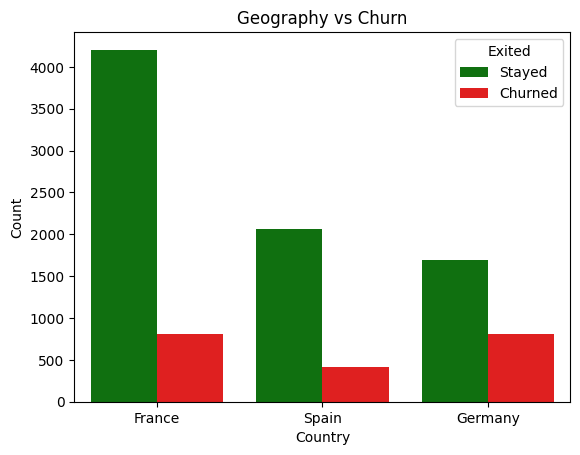

In [23]:
sb.countplot(x="Geography", hue="Exited", data=df, palette=["green", "red"])

mp.title("Geography vs Churn")
mp.xlabel("Country")
mp.ylabel("Count")
mp.legend(title="Exited", labels=["Stayed", "Churned"])
mp.show()

# **Gender vs Churn graph understanding** :
- Female customers are leaving at a noticeably higher rate than male customers, which points to a gap in how the bank is serving them.

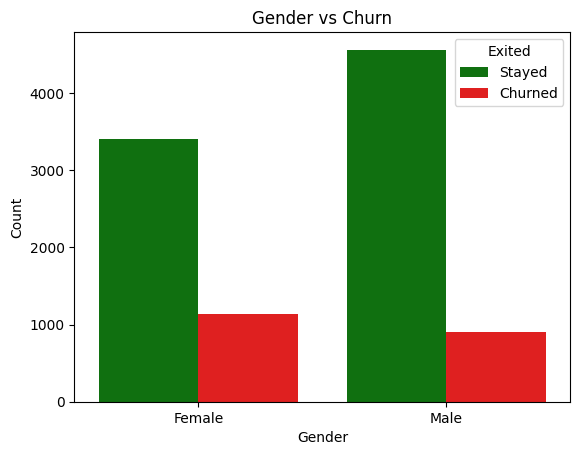

In [24]:
sb.countplot(x="Gender", hue="Exited", data=df, palette=["green", "red"])

mp.title("Gender vs Churn")
mp.xlabel("Gender")
mp.ylabel("Count")
mp.legend(title="Exited", labels=["Stayed", "Churned"])
mp.show()

# **Active Member vs Churn graph  undertanding** :
- Customers who stopped engaging with the bank are nearly twice as likely to leave — disengagement is an early warning sign the bank is missing.

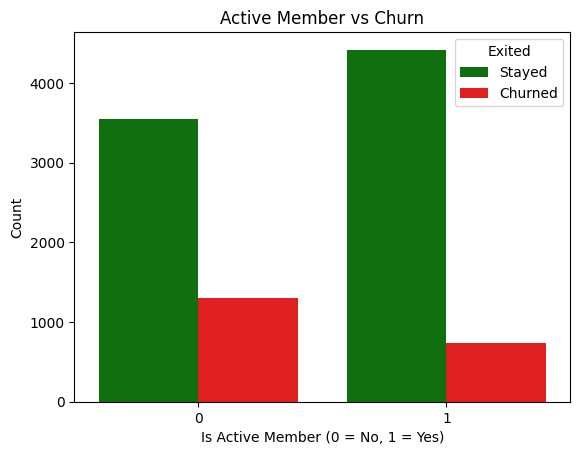

In [25]:
sb.countplot(x="IsActiveMember", hue="Exited", data=df, palette=["green", "red"])

mp.title("Active Member vs Churn")
mp.xlabel("Is Active Member (0 = No, 1 = Yes)")
mp.ylabel("Count")
mp.legend(title="Exited", labels=["Stayed", "Churned"])
mp.show()

# **Balance vs Churn grah understanding** :
- Customers with more money in their accounts are still choosing to leave, which means the bank is losing high-value customers it can least afford to lose.

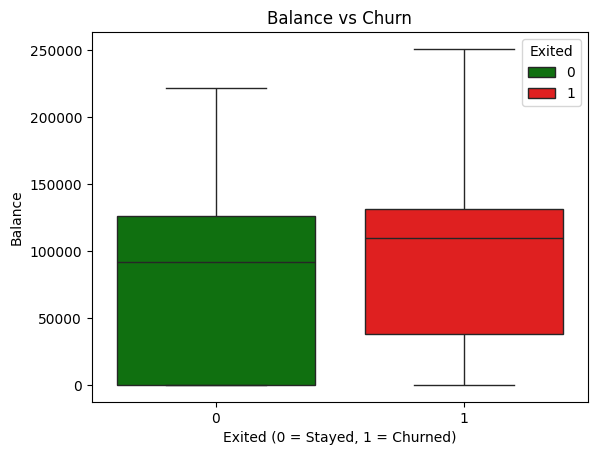

In [26]:
sb.boxplot(x="Exited", y="Balance", data=df,hue="Exited" ,palette=["green", "red"])

mp.title("Balance vs Churn")
mp.xlabel("Exited (0 = Stayed, 1 = Churned)")
mp.ylabel("Balance")
mp.show()

# **Credit Score vs Churn graph understanding** :
- A customer's credit score tells the bank nothing about whether they will stay or leave — it should not be used as a retention indicator.

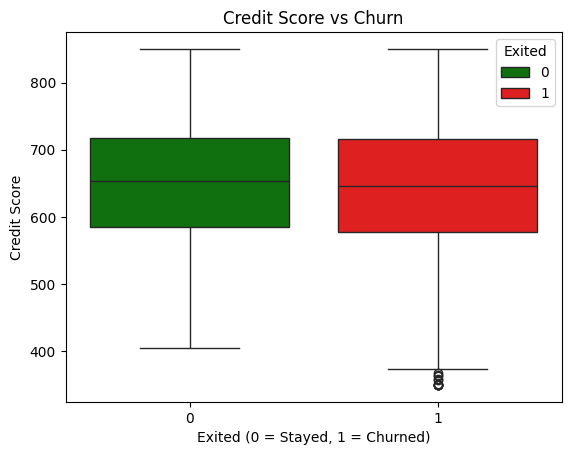

In [27]:
sb.boxplot(x="Exited", y="CreditScore", data=df, hue="Exited" ,palette=["green", "red"])

mp.title("Credit Score vs Churn")
mp.xlabel("Exited (0 = Stayed, 1 = Churned)")
mp.ylabel("Credit Score")
mp.show()

# **Heatmap graph understanding** : 
- Age is the only customer detail that has a clear, direct link to churn — everything else requires a deeper look to find the real patterns.

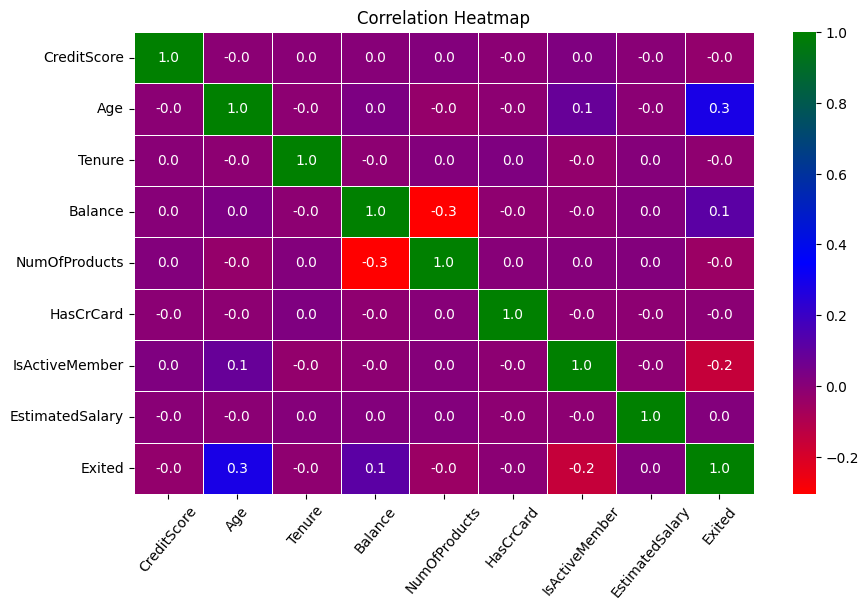

In [28]:

colors = ["red", "blue", "green"]
mp.figure(figsize=(10, 6))
my_cmap = LinearSegmentedColormap.from_list("mycolors", colors)
sb.heatmap(df.corr(numeric_only=True), annot=True, fmt=".1f", cmap=my_cmap, linewidths=0.5)

mp.title("Correlation Heatmap")
mp.xticks(rotation=50)
mp.show()

# **Root Cause Analysis**
- Goal: Find which factors are most responsible for churn


 Root Cause Analysis 

Churn Rate by Number of Products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00

Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67

Churn Rate by Active Member Status (0=Inactive, 1=Active):
IsActiveMember
0    26.85
1    14.27

Churn Rate by Gender:
Gender
Female    25.07
Male      16.46

Churn Rate by Age Group:
AgeGroup
18-30     7.50
31-40    12.09
41-50    33.97
51-60    56.21
60+      24.78


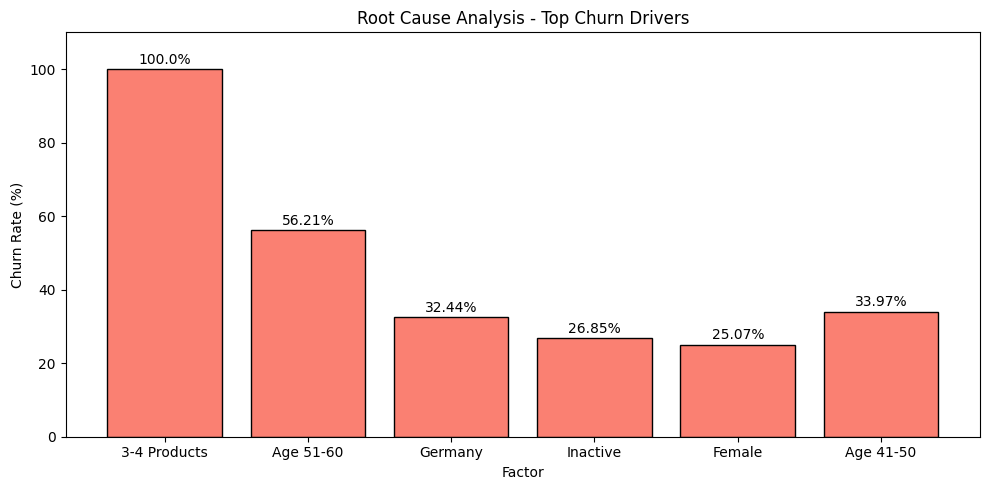

In [29]:
print("\n Root Cause Analysis \n")

# Churn Rate by Each Factor :

# Churn rate by number of products
print("Churn Rate by Number of Products:")
print(round(df.groupby("NumOfProducts")["Exited"].mean() * 100, 2).to_string())

# Churn rate by geography
print("\nChurn Rate by Geography:")
print(round(df.groupby("Geography")["Exited"].mean() * 100, 2).to_string())

# Churn rate by active member status
print("\nChurn Rate by Active Member Status (0=Inactive, 1=Active):")
print(round(df.groupby("IsActiveMember")["Exited"].mean() * 100, 2).to_string())

# Churn rate by gender
print("\nChurn Rate by Gender:")
print(round(df.groupby("Gender")["Exited"].mean() * 100, 2).to_string())


# Age Group Analysis (Root Cause) :
bins_rca = [18, 30, 40, 50, 60, 100]
labels_rca = ["18-30", "31-40", "41-50", "51-60", "60+"]
df["AgeGroup"] = pd.cut(df["Age"], bins=bins_rca, labels=labels_rca)

print("\nChurn Rate by Age Group:")
print(round(df.groupby("AgeGroup")["Exited"].mean() * 100, 2).to_string())


# Root Cause Bar Chart : Showing (Top Churn Factors)
# Compare churn rate across all key segments visually
# Taking  highest mean from each factor class
factors = {
    "3-4 Products": 100.00,      
    "Age 51-60":    56.21,
    "Germany":      32.44,
    "Inactive":     26.85,
    "Female":       25.07,
    "Age 41-50":    33.97,
}

mp.figure(figsize=(10, 5))
mp.bar(factors.keys(), factors.values(), color="salmon", edgecolor="black")

mp.title("Root Cause Analysis - Top Churn Drivers")
mp.ylabel("Churn Rate (%)")
mp.xlabel("Factor")
mp.ylim(0, 110)
for i, (key, val) in enumerate(factors.items()):
    mp.text(i, val + 1.5, f"{val}%", ha="center", fontsize=10)
mp.savefig('rca_op.png')
mp.tight_layout()
mp.show()


# **Hypothesis Testing** 
- Goal: Check if the churn differences we see are real or just random
- Method : Using Chi-Square Test for categories and T-Test for numbers


 Hypothesis Testing 

Ask a question: Is the difference we see real or just by chance?

Rule: If p-value < 0.05, the difference is real (significant).
      If p-value > 0.05, the difference might be random (not significant).

T-Test: Age vs Churn
Churned customers - Average Age : 44.84
Stayed customers  - Average Age : 37.41
P-Value : 1.239931e-186
Result: Age difference is Real. Older customers churn more - confirmed.

T-Test: Balance vs Churn
Churned customers - Average Balance : 91108.54
Stayed customers  - Average Balance : 72745.3
P-Value : 1.275563e-32
Result: Balance difference is Real. Higher balance customers churn more - confirmed.

Chi-Square Test: Geography vs Churn
P-Value : 3.830318e-66
Result: Geography does affect churn. Germany's high rate is real, not random.

Chi-Square Test: Gender vs Churn
P-Value : 2.248210e-26
Result: Gender Does affect churn. Female churn rate is significantly higher.

Chi-Square Test: Active Member vs Churn
P-Value : 8.785858e-55
Result: Acti

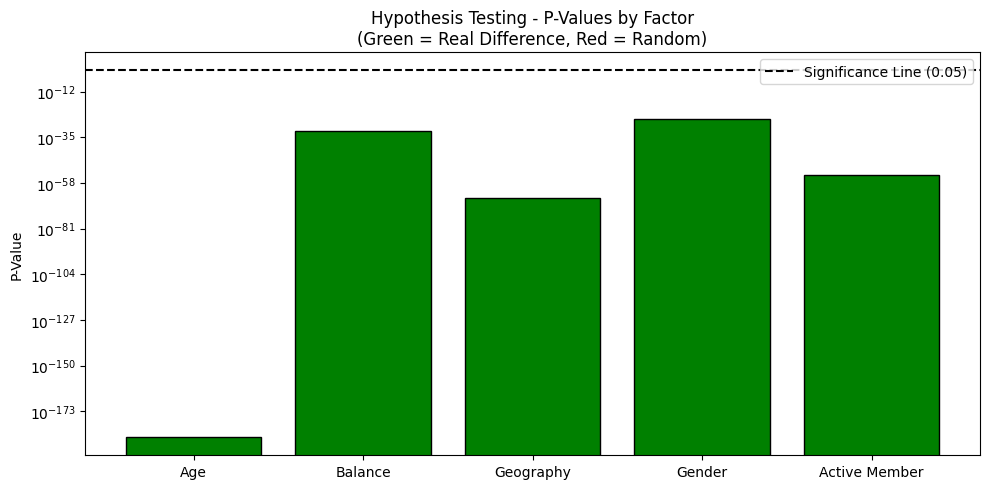

[np.float64(1.2399313093427934e-186), np.float64(1.275563319152543e-32), np.float64(3.8303176053541544e-66), np.float64(2.2482100097131755e-26), np.float64(8.785858269303705e-55)]


In [30]:

print("\n Hypothesis Testing ")
print("""
Ask a question: Is the difference we see real or just by chance?

Rule: If p-value < 0.05, the difference is real (significant).
      If p-value > 0.05, the difference might be random (not significant).
""")


# T-Test: Is Age different between churned and non-churned customers?
churned = df[df["Exited"] == 1]["Age"]
stayed  = df[df["Exited"] == 0]["Age"]

t_stat, p_value = stats.ttest_ind(churned, stayed)

print("T-Test: Age vs Churn")
print(f"Churned customers - Average Age : {round(churned.mean(), 2)}")
print(f"Stayed customers  - Average Age : {round(stayed.mean(), 2)}")
print(f"P-Value : {p_value:4e}")

if p_value < 0.05:
    print("Result: Age difference is Real. Older customers churn more - confirmed.")
else:
    print("Result: Age difference might be random.")


# T-Test: Is Balance different between churned and non-churned customers?
churned_bal = df[df["Exited"] == 1]["Balance"]
stayed_bal  = df[df["Exited"] == 0]["Balance"]

t_stat2, p_value2 = stats.ttest_ind(churned_bal, stayed_bal)

print("\nT-Test: Balance vs Churn")
print(f"Churned customers - Average Balance : {round(churned_bal.mean(), 2)}")
print(f"Stayed customers  - Average Balance : {round(stayed_bal.mean(), 2)}")
print(f"P-Value : {p_value2:4e}")

if p_value2 < 0.05:
    print("Result: Balance difference is Real. Higher balance customers churn more - confirmed.")
else:
    print("Result: Balance difference might be random.")

# Chi-Square Test: Does Geography affect churn?
geo_table = pd.crosstab(df["Geography"], df["Exited"])
chi2, p_value3, dof, expected = stats.chi2_contingency(geo_table)

print("\nChi-Square Test: Geography vs Churn")
print(f"P-Value : {p_value3:4e}")

if p_value3 < 0.05:
    print("Result: Geography does affect churn. Germany's high rate is real, not random.")
else:
    print("Result: Geography may not affect churn.")


# Chi-Square Test: Does Gender affect churn?
gender_table = pd.crosstab(df["Gender"], df["Exited"])
chi2_g, p_value4, dof_g, expected_g = stats.chi2_contingency(gender_table)

print("\nChi-Square Test: Gender vs Churn")
print(f"P-Value : {p_value4:4e}")

if p_value4 < 0.05:
    print("Result: Gender Does affect churn. Female churn rate is significantly higher.")
else:
    print("Result: Gender may not affect churn.")


# Chi-Square Test: Does Active Member status affect churn?
active_table = pd.crosstab(df["IsActiveMember"], df["Exited"])
chi2_a, p_value5, dof_a, expected_a = stats.chi2_contingency(active_table)

print("\nChi-Square Test: Active Member vs Churn")
print(f"P-Value : {p_value5:4e}")

if p_value5 < 0.05:
    print("Result: Active Member status Does affect churn. Inactive customers churn more - confirmed.")
else:
    print("Result: Active member status may not affect churn.")


# Hypothesis Testing Summary 
tests = ["Age", "Balance", "Geography", "Gender", "Active Member"]
p_values = [p_value, p_value2, p_value3, p_value4, p_value5]
colors = ["green" if p < 0.05 else "red" for p in p_values]

mp.figure(figsize=(10, 5))
mp.bar(tests, p_values, color=colors, edgecolor="black")
mp.axhline(y=0.05, color="black", linestyle="--", label="Significance Line (0.05)")

mp.yscale("log")
mp.title("Hypothesis Testing - P-Values by Factor\n(Green = Real Difference, Red = Random)")
mp.ylabel("P-Value")
mp.legend()
mp.savefig('hypo_op.png')
mp.tight_layout()
mp.show()
print(p_values)

# **Regression Analysis** 
- Goal:  Statistically profile which customer attributes drive churn
- Method : Using Logistic Regression because the answer is Yes or No (churn or not)


 Statistical Diagnostic Analysis : 

Using Statsmodels Logit to diagnose historical customer churn.
This will generate P-values and Coefficients to prove which factors 
are statistically reliable drivers of churn.

Optimization terminated successfully.
         Current function value: 0.434991
         Iterations 6
             Statistical Diagnostic Report              
                           Logit Regression Results                           
Dep. Variable:                 Exited   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9989
Method:                           MLE   Df Model:                           10
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.1395
Time:                        21:06:28   Log-Likelihood:                -4349.9
converged:                       True   LL-Null:                       -5054.9
Covariance Type:            nonrobust   LLR p-value:                7.03

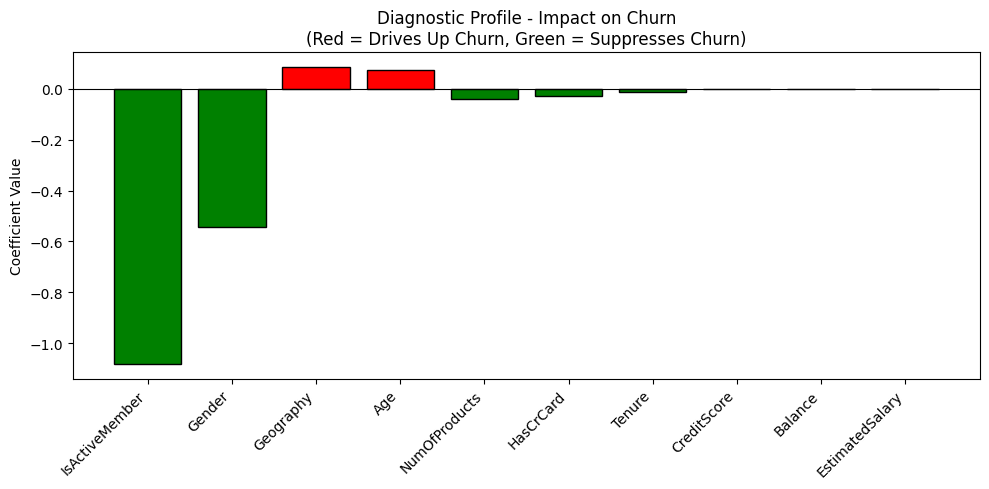

In [31]:

print("\n Statistical Diagnostic Analysis : ")
print("""
Using Statsmodels Logit to diagnose historical customer churn.
This will generate P-values and Coefficients to prove which factors 
are statistically reliable drivers of churn.
""")

# Data Preparation
df_reg = df.copy()
df_reg = df_reg.drop(columns=['AgeGroup'])  

# Convert text categories to distinct numeric levels
le = LabelEncoder()
df_reg["Geography"] = le.fit_transform(df_reg["Geography"]) 
df_reg["Gender"]    = le.fit_transform(df_reg["Gender"])      



# Feature Selection
X = df_reg.drop(columns=["Exited"])   # Independent variables
y = df_reg["Exited"]                  # Target variable (Churn)

# Intercept Calculation
X_with_constant = sm.add_constant(X)

# Fit Model 
model = sm.Logit(y, X_with_constant)
results = model.fit()


print("             Statistical Diagnostic Report              ")
print("=" * 78)
print(results.summary())



# Feature Significance (Sorting by Impact)
# Drop 'const' , to only include actionable customer features
feature_names = X.columns
coefficients  = results.params.drop("const")
p_values      = results.pvalues.drop("const")

coef_df = pd.DataFrame({
    "Feature":     feature_names,
    "Coefficient": coefficients.values,
    "P-Value":     p_values.values
})

# Add status tags based on the 0 P-value threshold
coef_df["Significance"] = coef_df["P-Value"].apply(lambda p: "Statistically Significant" if p < 0.05 else "Statistically Not Significant")
coef_df["Abs_Value"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs_Value", ascending=False)

print("\n        Customer Feature Impact Profiling:      ")
print("=" * 70)
print(coef_df[["Feature", "Coefficient", "P-Value", "Significance"]].to_string(index=False))


# Features Impact 
mp.figure(figsize=(10, 5))
colors = ["red" if c > 0 else "green" for c in coef_df["Coefficient"]]
mp.bar(coef_df["Feature"], coef_df["Coefficient"], color=colors, edgecolor="black")
mp.axhline(y=0, color="black", linewidth=0.8)

mp.title("Diagnostic Profile - Impact on Churn\n(Red = Drives Up Churn, Green = Suppresses Churn)")
mp.ylabel("Coefficient Value")
mp.xticks(rotation=45, ha="right")
mp.savefig('reg_op.png')
mp.tight_layout()
mp.show()


# After observing and understanding from all the charts :

# **Key Insights** : 

1. Age - Older customers are more likely to leave the bank.

2. Number of Products — Customers with 3 or 4 products almost always leave.

3. Geography - Germany has the highest number of customers leaving.

4. Gender - Female customers leave more than male customers.

5. Active Member - Customers who don't use the bank actively tend to leave.

6. Balance - Customers with higher balance are more likely to leave.

7. Credit Score - Has no strong impact on whether a customer leaves or stays.


# **Recommendations** : 

1. Stop over-selling products to existing customers — The data is clear that loading a customer with 3 or 4 products pushes them out, not deeper in.

2. Call Germany a problem market, not a data point — A 32% churn rate in one country while the others sit at 16% is a business failure, not a statistical variation.

3. Treat inactive customers as at-risk customers — By the time someone stops using the bank, half the decision to leave is already made.

4. Build something specific for the 51–60 age group — They are the bank's most valuable demographic and also its highest churn segment right now.

5. Stop using credit score to predict loyalty — The data shows zero relationship between the two; using it as a proxy for retention is a wasted effort.
